# Day 3 · Classification Fundamentals
Predict **Needs Water** with sklearn `LogisticRegression`; evaluate with confusion matrix and ROC-AUC.

The dataset has no `Needs_Water` column, so it is defined here as a field rule: **rainfall below 500 mm and no irrigation**. (In this dataset, weather/soil/crop columns are statistically independent of rainfall, so a rainfall-only label can't be predicted without rainfall itself; the rule is an assumption you can change in one line. 8% of labels are flipped to mimic imperfect field reports; with a perfectly deterministic rule the score would be a meaningless 1.0.) Yield is excluded from the features since it is an outcome.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, classification_report

rule = ((df["Rainfall_mm"] < 500) & (~df["Irrigation_Used"])).astype(int)
flip = np.random.default_rng(0).random(len(df)) < 0.08      # 8% label noise: field reports are imperfect
df["Needs_Water"] = np.where(flip, 1 - rule, rule)
print(df["Needs_Water"].value_counts(normalize=True).round(3))

feats = df.drop(columns=["Needs_Water", "Yield_tons_per_hectare"])
X = pd.get_dummies(feats, columns=["Region", "Soil_Type", "Crop", "Weather_Condition"], drop_first=True).astype(float)
y = df["Needs_Water"].to_numpy()

rng = np.random.default_rng(42); idx = rng.permutation(len(df)); cut = int(0.8 * len(df))
tr, te = idx[:cut], idx[cut:]
scaler = StandardScaler().fit(X.iloc[tr])
Xtr, Xte = scaler.transform(X.iloc[tr]), scaler.transform(X.iloc[te])

Needs_Water
0    0.733
1    0.267
Name: proportion, dtype: float64


In [3]:
clf = LogisticRegression(max_iter=500).fit(Xtr, y[tr])
pred, proba = clf.predict(Xte), clf.predict_proba(Xte)[:, 1]
print("accuracy:", round((pred == y[te]).mean(), 4))
print("ROC-AUC :", round(roc_auc_score(y[te], proba), 4))
print(classification_report(y[te], pred, digits=3, zero_division=0))

accuracy: 0.9188
ROC-AUC : 0.8701
              precision    recall  f1-score   support

           0      0.920     0.974     0.946    146796
           1      0.915     0.765     0.834     53204

    accuracy                          0.919    200000
   macro avg      0.918     0.870     0.890    200000
weighted avg      0.919     0.919     0.916    200000



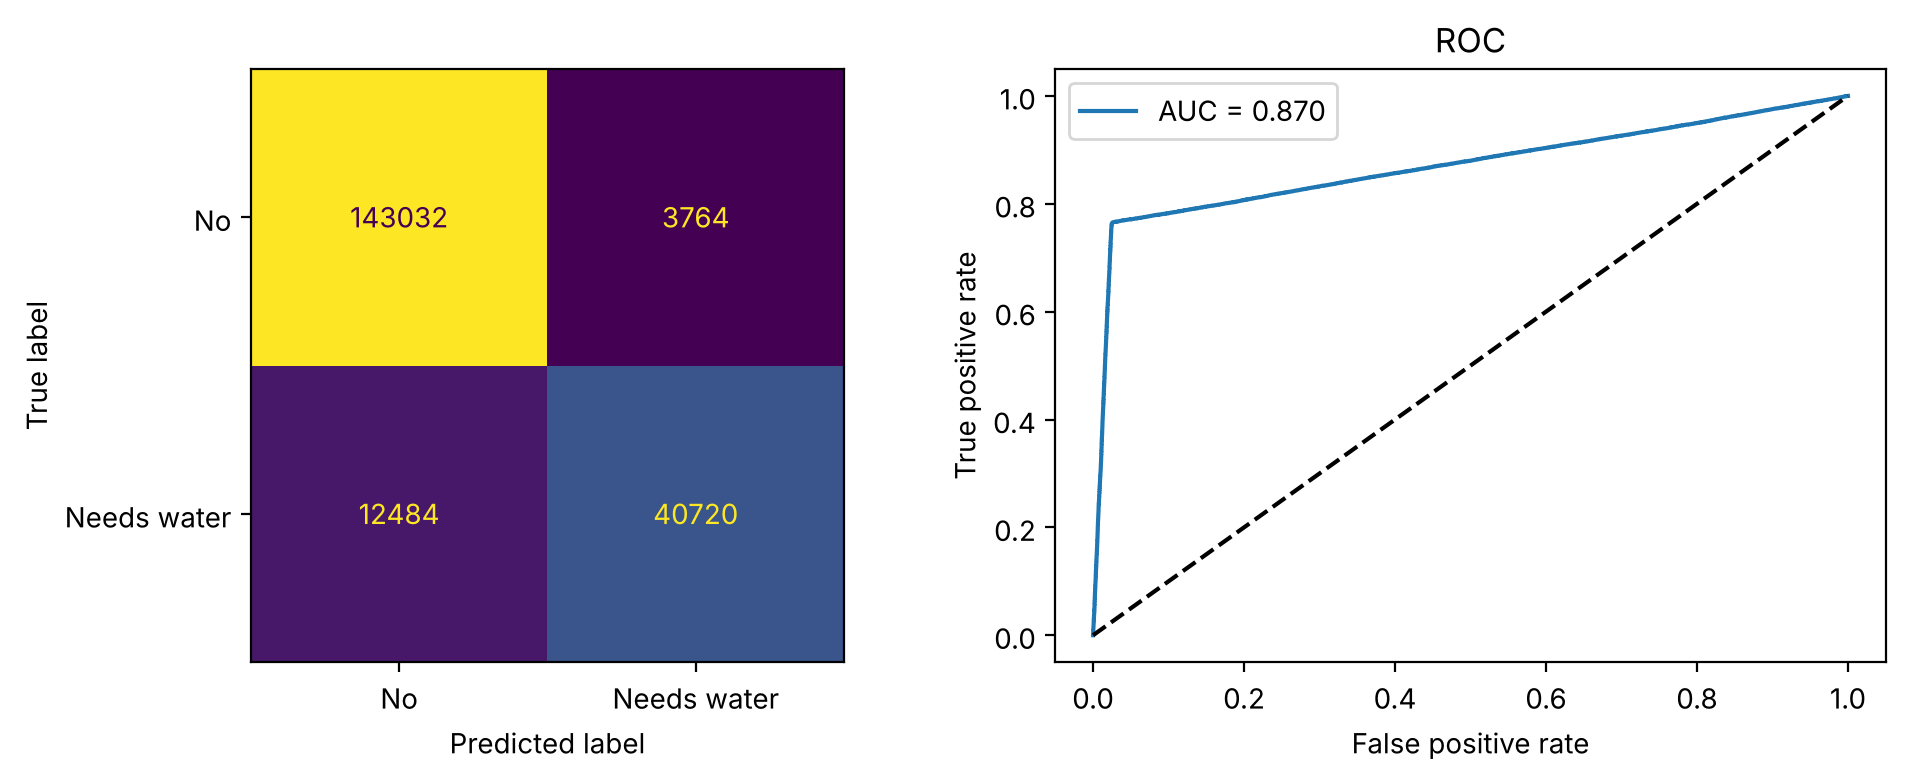

Irrigation_Used           -1.467088
Rainfall_mm               -1.447095
Soil_Type_Loam             0.006987
Days_to_Harvest            0.004831
Region_North               0.003953
Weather_Condition_Sunny    0.003259
Fertilizer_Used           -0.002936
Region_West                0.002784
dtype: float64

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y[te], pred), display_labels=["No", "Needs water"]).plot(ax=ax[0], colorbar=False)
fpr, tpr, _ = roc_curve(y[te], proba)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y[te], proba):.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].set_title("ROC"); ax[1].legend()
plt.tight_layout(); plt.show()

coef = pd.Series(clf.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
coef.head(8)